# 03 · Modelado: líneas base y clasificador TF-IDF + Regresión Logística

Objetivo: construir el modelo base (`model_v1`) y medir su desempeño **sin tocar el conjunto ciego**. Toda la validación es cruzada, estratificada por dimensión y **por grupo de URL** (`StratifiedGroupKFold`): las normas que comparten URL caen en el mismo pliegue, para que el modelo nunca sea evaluado sobre un duplicado de algo que vio en entrenamiento.

Contenido: (1) pisos de referencia; (2) el pipeline y sus decisiones; (3) validación cruzada por grupo con intervalos; (4) desempeño por clase y matriz de confusión; (5) ablaciones (qué aporta cada decisión) y comparación con otras técnicas; (6) interpretabilidad; (7) entrenamiento y guardado de `model_v1`.

In [1]:
import json, os, subprocess, sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
from utils import load_config, setup_logging, set_seed, CLASSES
cfg = load_config(); set_seed(cfg["seed"]); setup_logging()
RES = ROOT / "results/metrics"; FIG = ROOT / "results/figures"; RES.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
print("raíz del repositorio:", ROOT)

raíz del repositorio: /home/claude/repo_genial


In [2]:
from data_processing import load_splits
from model import build_model, model_params
from genial_clf import baselines, classic
from genial_clf.optimize import cv_score, BASELINE
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
sp = load_splits(cfg); train = sp["train"]; t = cfg["columns"]["target"]
X, y, g = train["texto"].to_numpy(), train[t].to_numpy(), train["grupo_url"].to_numpy()
print("entrenamiento:", len(train), "normas ·", train[t].value_counts().to_dict())

entrenamiento: 673 normas · {'Pedagógico': 246, 'Ética': 219, 'Administrativo': 100, 'Protección de Datos': 58, 'Técnico': 50}


## 1. Pisos de referencia

Antes de cualquier modelo: ¿qué exactitud da adivinar siempre la clase mayoritaria y qué da usar solo un metadato (el tipo de norma: ley, resolución, guía…) sin leer el texto? Todo lo que el clasificador no supere con holgura no justifica su coste.

In [3]:
piso = baselines.arithmetic_floor(train[t].value_counts().to_dict()); print("clase mayoritaria:", {k: round(v, 3) for k, v in piso.items()})
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=cfg["seed"])
acc_m, f1_m = [], []
for tr, va in cv.split(X, y, g):
    mb = baselines.MetadataBaseline().fit(train.iloc[tr], t); p = mb.predict(train.iloc[va])
    acc_m.append(accuracy_score(y[va], p)); f1_m.append(f1_score(y[va], p, average="macro"))
print("metadatos (sin texto): exactitud %.3f ± %.3f · F1 macro %.3f ± %.3f" % (np.mean(acc_m), np.std(acc_m), np.mean(f1_m), np.std(f1_m)))

clase mayoritaria: {'accuracy': 0.366, 'f1_macro': 0.107}


metadatos (sin texto): exactitud 0.484 ± 0.033 · F1 macro 0.347 ± 0.032


## 2. El pipeline

`build_model()` (en `src/model.py`) devuelve `TfidfVectorizer → LogisticRegression`. Decisiones y motivo:

| Decisión | Valor | Por qué |
|---|---|---|
| n-gramas | 1-2 | los bigramas capturan «protección datos», «inteligencia artificial», «uso ético» |
| `max_features` | 5 000 | más *features* que ejemplos (673) → se limita el vocabulario a lo frecuente |
| `sublinear_tf` | sí | amortigua títulos con términos repetidos |
| `class_weight` | `balanced` | desbalance 4.7:1; sin él, Técnico y Administrativo casi no se predicen |
| `C` | 1.0 | valor por defecto, revisado en el cuaderno 04 |
| solver | `lbfgs`, multinomial | problema pequeño, convexo |

In [4]:
pipe = build_model(**BASELINE, seed=cfg["seed"]); print(pipe); print(model_params(pipe))

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, ngram_range=(1, 2),
                                 sublinear_tf=True)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=3000,
                                    random_state=2026))])
{'C': 1.0, 'class_weight': 'balanced', 'max_features': 5000, 'ngram_range': [1, 2], 'min_df': 1, 'sublinear_tf': True, 'n_vocab': None}


## 3. Validación cruzada por grupo

Cinco pliegues; se reporta F1 macro de validación y de entrenamiento por pliegue. El *gap* entre ambos anticipa el diagnóstico de sobreajuste de la Semana 3 (`anexos/overfitting_analysis.ipynb`).

In [5]:
r, folds = cv_score(build_model, BASELINE, X, y, g, seed=cfg["seed"], return_folds=True)
print("F1 macro validación por pliegue:", [round(f, 3) for f in folds])
print("media %.3f ± %.3f · entrenamiento %.3f · gap %.2f" % (r["val_f1"], r["val_std"], r["train_f1"], r["gap"]))
pred_cv = classic.cross_validate(train, cfg)          # predicciones fuera de muestra, top-2 y confianza
print("exactitud %.3f · F1 macro %.3f · top-2 %.3f" % (accuracy_score(pred_cv["y_true"], pred_cv["pred"]), f1_score(pred_cv["y_true"], pred_cv["pred"], average="macro"), ((pred_cv["pred"] == pred_cv["y_true"]) | (pred_cv["pred_2"] == pred_cv["y_true"])).mean()))

F1 macro validación por pliegue: [0.551, 0.539, 0.527, 0.584, 0.535]
media 0.547 ± 0.020 · entrenamiento 0.942 · gap 0.40


exactitud 0.594 · F1 macro 0.547 · top-2 0.837


## 4. Desempeño por clase

Las clases pequeñas (Técnico 63 normas en el corpus, Administrativo 120) son las difíciles: comparten vocabulario con Pedagógico y Ética. Protección de Datos, en cambio, tiene léxico propio y se reconoce bien pese a ser minoritaria.

                     precision    recall  f1-score   support

         Pedagógico      0.688     0.618     0.651       246
              Ética      0.602     0.703     0.648       219
     Administrativo      0.416     0.320     0.362       100
Protección de Datos      0.783     0.810     0.797        58
            Técnico      0.254     0.300     0.275        50

           accuracy                          0.594       673
          macro avg      0.549     0.550     0.547       673
       weighted avg      0.595     0.594     0.592       673



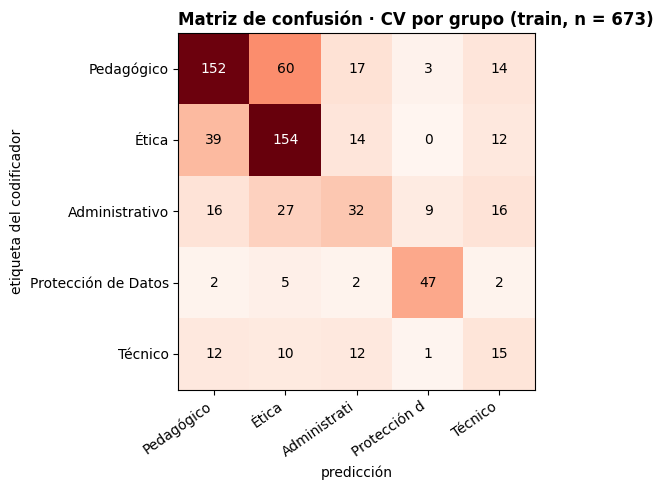

In [6]:
print(classification_report(pred_cv["y_true"], pred_cv["pred"], labels=CLASSES, digits=3))
cm = confusion_matrix(pred_cv["y_true"], pred_cv["pred"], labels=CLASSES)
fig, ax = plt.subplots(figsize=(6.2, 5)); im = ax.imshow(cm, cmap="Reds")
ax.set_xticks(range(5)); ax.set_xticklabels([c[:12] for c in CLASSES], rotation=35, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(CLASSES)
for i in range(5):
    for j in range(5):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("predicción"); ax.set_ylabel("etiqueta del codificador"); ax.set_title("Matriz de confusión · CV por grupo (train, n = %d)" % len(train), loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "18_confusion_cv_train.png", dpi=300, facecolor="white"); plt.show()

## 5. Ablaciones y otras técnicas

Resultados del experimento del Sprint 3 sobre el corpus completo (validación cruzada por grupo, n = 813; `anexos/experimento_sprint3.ipynb`): qué cambia al quitar la ponderación de clases, los bigramas o reducir el vocabulario, y cómo se comparan SVM lineal y las líneas base. La conclusión que fija el modelo base: **la ponderación de clases es la decisión que más importa** (F1 macro 0.587 vs 0.475 sin ella); el resto mueve el F1 en el margen del ruido entre pliegues.

In [7]:
display(pd.read_csv(RES / "ablaciones_cv.csv").round(3))
cp = pd.read_csv(RES / "comparacion_pareada.csv"); display(cp[["rama", "n", "exactitud", "IC95 exactitud", "F1 macro", "IC95 F1 macro", "top-2", "κ vs etiqueta original"]].round(3))
print("(comparación pareada sobre el conjunto ciego, Sprint 3; McNemar en results/metrics/mcnemar.csv)")

,variante,exactitud,F1 macro,F1 Pedagógico,F1 Ética,F1 Administrativo,F1 Protección de Datos,F1 Técnico
0,RL balanceada (configuración elegida),0.635,0.587,0.709,0.671,0.406,0.797,0.353
1,RL sin ponderar clases,0.622,0.475,0.706,0.657,0.211,0.769,0.031
2,"RL balanceada, C = 3",0.637,0.581,0.720,0.664,0.409,0.783,0.327
3,"SVM lineal balanceada, C = 0.5",0.645,0.578,0.732,0.680,0.368,0.783,0.328
4,"RL balanceada, solo unigramas",0.620,0.576,0.684,0.663,0.391,0.776,0.366
5,"RL balanceada, caracteres 3-5",0.609,0.573,0.690,0.635,0.407,0.786,0.350


,rama,n,exactitud,IC95 exactitud,F1 macro,IC95 F1 macro,top-2,κ vs etiqueta original
0,mayoritaria,125,0.360,"[0.281, 0.447]",0.106,"[0.087, 0.124]",0.360,0.000
1,metadata,125,0.544,"[0.457, 0.629]",0.322,"[0.251, 0.394]",0.608,0.325
2,clasico,125,0.688,"[0.602, 0.763]",0.617,"[0.505, 0.712]",0.872,0.555
3,svm,125,0.720,"[0.636, 0.791]",0.646,"[0.535, 0.741]",0.880,0.601


(comparación pareada sobre el conjunto ciego, Sprint 3; McNemar en results/metrics/mcnemar.csv)


## 6. Interpretabilidad: términos con mayor peso por dimensión

Coeficientes de la regresión logística multinomial sobre el vocabulario TF-IDF. Sirven para comprobar que el modelo aprende léxico de la dimensión y no artefactos (nombres de países, de instituciones o fechas).

In [8]:
pipe.fit(X, y)
tt = classic.top_terms(pipe, k=12) if "tfidf" in pipe.named_steps else None
if tt is None:
    vocab = np.array(pipe.named_steps[list(pipe.named_steps)[0]].get_feature_names_out()); coef = pipe.named_steps[list(pipe.named_steps)[-1]].coef_
    tt = pd.DataFrame({c: vocab[np.argsort(-coef[i])[:12]] for i, c in enumerate(pipe.classes_)})
display(tt)

,dimension,terminos
0,Administrativo,"resolución, 2025, mediante resolución, polític..."
1,Pedagógico,"guía, aprendizaje, enseñanza, en, aula, genera..."
2,Protección de Datos,"datos, de privacidad, personales, datos person..."
3,Técnico,"sistemas de, robótica, sistemas, ley, national..."
4,Ética,"ética, ético, uso, principios, éticos, el uso,..."


## 7. Entrenar y guardar `model_v1`

`src/train.py` entrena con todo `train.csv`, registra la validación cruzada en los metadatos y guarda `models/model_v1.pkl` + `models/model_v1.json`. El modelo optimizado (`best_model`) se entrena en el cuaderno 04 y ambos se evalúan a ciegas en el 05.

In [9]:
import train as T
meta = T.train_and_save("model_v1", BASELINE, train, cfg, "configuración base (cuaderno 03)")
print(json.dumps(meta, ensure_ascii=False, indent=1, default=float))

2026-10-11 04:52:24,495 · INFO · model · modelo guardado en /home/claude/repo_genial/models/model_v1.pkl


2026-10-11 04:52:24,496 · INFO · train · model_v1: CV val F1 0.547 (gap 0.40) · umbral de confianza 0.50 (tramo automático 14 %, exactitud 0.87) · guardado


{
 "nombre": "model_v1",
 "origen_parametros": "configuración base (cuaderno 03)",
 "n_entrenamiento": 673,
 "cv_por_grupo": {
  "val_f1": 0.5470230127438471,
  "val_std": 0.020186637826681078,
  "train_f1": 0.942325936883811,
  "gap": 0.39530292413996393
 },
 "f1_entrenamiento": 0.9223208566262884,
 "umbral_confianza": 0.5,
 "calibracion_umbral": {
  "criterio": "exactitud del tramo automático ≥ 0.85 con ≥ 10% de normas automáticas (CV por grupo, train)",
  "objetivo_alcanzado": true,
  "umbral": 0.5,
  "fraccion_automatica": 0.13967310549777118,
  "exactitud_automatica": 0.8723404255319149,
  "curva": [
   {
    "umbral": 0.2,
    "fraccion_automatica": 1.0,
    "exactitud_automatica": 0.5943536404160475
   },
   {
    "umbral": 0.25,
    "fraccion_automatica": 0.9791976225854383,
    "exactitud_automatica": 0.6009104704097117
   },
   {
    "umbral": 0.3,
    "fraccion_automatica": 0.8068350668647846,
    "exactitud_automatica": 0.6500920810313076
   },
   {
    "umbral": 0.35,
    